# Experimento 06: Cuantización INT8, Latencia y Consumo de Recursos en ESP32-S3
## Evaluación Multi-Régimen en Hardware para el Sujeto S01 (Poblacional vs Zero-Shot vs Calibrado)

---

### 1. Contexto y Objetivos Científicos
En este experimento se evalúa la **viabilidad real de despliegue embebido** sobre el microcontrolador **ESP32-S3 (Xtensa Dual-Core LX7 @ 240 MHz con aceleración SIMD `ESP-NN`)**, contrastando sistemáticamente el desempeño del **Sujeto S01** a través de los tres regímenes de aprendizaje de la tesis:

1. **Régimen 1 — Poblacional / Pooled (Experimento 03):** Modelo global entrenado con toda la cohorte ($N=10$, incluyendo datos de S01). Representa el techo poblacional.
2. **Régimen 2 — Generalización Inter-Sujeto / Zero-Shot (Experimento 04 - LOSO):** Modelo entrenado con los otros 9 sujetos ($S02\dots S10$) y evaluado "en frío" sobre S01 (*Plug-and-Play*).
3. **Régimen 3 — Adaptado por Calibración Rápida / Fine-Tuned (Experimento 05):** Modelo de LOSO adaptado con el **10% de repeticiones de S01** (~5 segundos por gesto, estándar clínico).

---

### 2. Restricciones Críticas en Tiempo Real
* **Restricción de Búfer Circular:** $t_{\text{dsp}} + t_{\text{inference}} < S = 50\text{ ms}$ (evitar desbordamiento de búfer a 20 decisiones/seg).
* **Restricción Clínica de Farina et al.:** $\text{Controller Delay} = S (50\text{ ms}) + t_{\text{dsp}} + t_{\text{inference}} + t_{\text{voter}} (0.02\text{ ms}) + t_{\text{esp-now}} (0.85\text{ ms}) \le 100\text{ ms}$ (límite de percepción táctil y control motor fluido).
* **Presupuesto Físico de Memoria en ESP32-S3:**
  * **SRAM Interna:** 320 KB útiles para Tensor Arena, buffers de señal y FreeRTOS (sin depender de PSRAM externa lenta).
  * **Flash ROM:** Partición de aplicación de 3,342 KB (3.3 MB) en memoria SPI Flash de 16 MB.


In [1]:
import os
import sys
import time
import json
import shutil
import subprocess
from pathlib import Path

# 1. Configuración de Entorno TensorFlow y GPU
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# 2. Resolución dinámica de rutas
curr = Path.cwd().resolve()
intelligence_dir = None
project_root = None

while curr != curr.parent:
    if (curr / "intelligence" / "src").is_dir():
        intelligence_dir = curr / "intelligence"
        project_root = curr
        break
    elif (curr / "src").is_dir() and (curr / "src" / "config.py").is_file():
        intelligence_dir = curr
        project_root = curr.parent
        break
    curr = curr.parent

if intelligence_dir is None:
    raise RuntimeError("No se pudo localizar el directorio raíz 'intelligence'")

if str(intelligence_dir) not in sys.path:
    sys.path.insert(0, str(intelligence_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from micromlgen import port

from src import config, dataset, features

# Semillas globales de reproducibilidad
np.random.seed(config.RANDOM_STATE)
tf.random.set_seed(config.RANDOM_STATE)

# Directorios de trabajo
logs_dir = intelligence_dir / "src" / "experimentos" / "logs"
models_pooled_dir = logs_dir / "models_pooled"
models_loso_dir = logs_dir / "models_loso"
models_calib_dir = logs_dir / "models_calibrated"
embedded_dir = logs_dir / "embedded_models"

os.makedirs(embedded_dir, exist_ok=True)
firmware_dir = project_root / "firmware" / "Classifier"

# Localización de PlatformIO Core
pio_bin = shutil.which("pio") or "/home/cbe/.platformio/penv/bin/pio"
has_pio = Path(pio_bin).is_file()

print(f"[*] Entorno Inicializado Correctamente")
print(f"  - Raíz del Proyecto: {project_root}")
print(f"  - Versión de TensorFlow: {tf.__version__}")
print(f"  - Modelos Poblacionales: {models_pooled_dir}")
print(f"  - Modelos LOSO (Zero-Shot): {models_loso_dir}")
print(f"  - Modelos Calibrados: {models_calib_dir}")
print(f"  - Artefactos Embebidos (ESP32): {embedded_dir}")
print(f"  - PlatformIO CLI Disponible: {has_pio} ({pio_bin})")


I0000 00:00:1790549710.504886   54978 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[*] Entorno Inicializado Correctamente
  - Raíz del Proyecto: /home/cbe/Proyectos/MyoTensor_Tesis
  - Versión de TensorFlow: 2.21.0
  - Modelos Poblacionales: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/models_pooled
  - Modelos LOSO (Zero-Shot): /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/models_loso
  - Modelos Calibrados: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/models_calibrated
  - Artefactos Embebidos (ESP32): /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/embedded_models
  - PlatformIO CLI Disponible: True (/home/cbe/miniconda3/envs/tesis_env/bin/pio)


I0000 00:00:1790549711.369925   54978 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
TARGET_SUBJECT = "S01"
MUSCLES = ["ED", "FDS"]
GESTURES = config.GESTURES
WINDOW_SIZE = config.WINDOW_SIZE
STRIDE_MS = 50.0  # ms
ESP_NOW_LATENCY_MS = 0.85  # ms
VOTER_LATENCY_MS = 0.02  # ms

REGIMES = [
    ("Poblacional (Exp 03)", models_pooled_dir, "pooled_{muscle}_{model}", "pooled_{muscle}_scaler.joblib"),
    ("Zero-Shot LOSO (Exp 04)", models_loso_dir, f"loso_{{muscle}}_{{model}}_{TARGET_SUBJECT}", None),
    ("Calibrado 10% (Exp 05)", models_calib_dir, f"calib10_{{muscle}}_{{model}}_{TARGET_SUBJECT}", f"calib10_{{muscle}}_scaler_{TARGET_SUBJECT}.joblib")
]

def quantize_tcn_to_int8(keras_model, representative_samples):
    """
    Cuantiza un modelo CNN-TCN a INT8 Full Integer con TFLite.
    Forzado estricto de forma rank-3 (N, W, C) para evitar error de TFLite conv.cc:345.
    """
    converter_fp32 = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    tflite_fp32 = converter_fp32.convert()
    
    if representative_samples.ndim == 2:
        rep_3d = np.expand_dims(representative_samples, axis=-1)
    else:
        rep_3d = representative_samples
    
    def rep_data_gen():
        for sample in rep_3d:
            yield [np.expand_dims(sample, axis=0).astype(np.float32)]
            
    converter_int8 = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
    converter_int8.representative_dataset = rep_data_gen
    converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter_int8.inference_input_type = tf.int8
    converter_int8.inference_output_type = tf.int8
    tflite_int8 = converter_int8.convert()
    
    return tflite_fp32, tflite_int8

def quantize_lstm_model(keras_model):
    """
    Convierte y cuantiza un modelo CNN-LSTM a TFLite (FP32 y Dynamic Range/INT8).
    """
    converter_fp32 = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter_fp32.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
    converter_fp32._experimental_lower_tensor_list_ops = False
    tflite_fp32 = converter_fp32.convert()
    
    converter_quant = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter_quant.optimizations = [tf.lite.Optimize.DEFAULT]
    converter_quant.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
    converter_quant._experimental_lower_tensor_list_ops = False
    tflite_quant = converter_quant.convert()
    
    return tflite_fp32, tflite_quant

def evaluate_tflite_interpreter(tflite_bytes, X_test, y_test, is_int8=False, n_warmup=20, n_bench=200):
    """
    Ejecuta inferencia bit-a-bit con tf.lite.Interpreter y mide latencia unitaria.
    """
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    in_details = interpreter.get_input_details()[0]
    out_details = interpreter.get_output_details()[0]
    
    if X_test.ndim == 2:
        X_test = np.expand_dims(X_test, axis=-1)
    
    scale, zero_point = in_details.get("quantization", (0.0, 0))
    
    for i in range(min(n_warmup, len(X_test))):
        x_val = np.expand_dims(X_test[i], axis=0)
        if is_int8:
            x_val = np.clip(np.round(x_val / scale) + zero_point, -128, 127).astype(np.int8)
        interpreter.set_tensor(in_details['index'], x_val)
        interpreter.invoke()
        
    y_preds = []
    bench_times = []
    for i in range(len(X_test)):
        x_val = np.expand_dims(X_test[i], axis=0)
        if is_int8:
            x_val = np.clip(np.round(x_val / scale) + zero_point, -128, 127).astype(np.int8)
            
        if i < n_bench:
            t0 = time.perf_counter()
            interpreter.set_tensor(in_details['index'], x_val)
            interpreter.invoke()
            bench_times.append((time.perf_counter() - t0) * 1000.0)
            out_tensor = interpreter.get_tensor(out_details['index'])
        else:
            interpreter.set_tensor(in_details['index'], x_val)
            interpreter.invoke()
            out_tensor = interpreter.get_tensor(out_details['index'])
            
        y_preds.append(np.argmax(out_tensor))
        
    y_preds = np.array(y_preds)
    acc = accuracy_score(y_test, y_preds)
    f1 = f1_score(y_test, y_preds, average='macro', zero_division=0)
    prec = precision_score(y_test, y_preds, average='macro', zero_division=0)
    rec = recall_score(y_test, y_preds, average='macro', zero_division=0)
    mean_lat_pc = float(np.mean(bench_times)) if bench_times else 0.0
    
    return {
        "accuracy": float(acc),
        "f1_macro": float(f1),
        "precision_macro": float(prec),
        "recall_macro": float(rec),
        "mean_latency_pc_ms": mean_lat_pc,
        "predictions": y_preds
    }

def profile_dsp_features_time(X_raw_sample, subject="S01", muscle="ED", n_reps=100):
    """
    Mide el tiempo de extracción de las 6 características de Hudgins por ventana.
    """
    times = []
    for _ in range(n_reps):
        t0 = time.perf_counter()
        feat = features.extract_features(X_raw_sample[:1], subject=subject, muscle=muscle)
        times.append((time.perf_counter() - t0) * 1000.0)
    return float(np.mean(times))

def export_c_byte_array(byte_data, out_path, array_name="g_model_data"):
    """
    Exporta un array binario TFLite a archivos C++ NN_model.h y NN_model.cpp con alineación 16B para ESP-NN SIMD.
    """
    h_content = f"""#ifndef NN_MODEL_H
#define NN_MODEL_H

extern const unsigned char {array_name}[];
extern const int {array_name}_len;

#endif // NN_MODEL_H
"""
    with open(out_path.with_suffix(".h"), "w", encoding="utf-8") as f:
        f.write(h_content)
        
    cpp_lines = [f'#include "{out_path.stem}.h"', f'alignas(16) const unsigned char {array_name}[] = {{']
    hex_bytes = [f'0x{b:02x}' for b in byte_data]
    chunk_size = 16
    for i in range(0, len(hex_bytes), chunk_size):
        cpp_lines.append("  " + ", ".join(hex_bytes[i:i+chunk_size]) + ",")
    cpp_lines.append("};")
    cpp_lines.append(f"const int {array_name}_len = {len(byte_data)};\n")
    
    with open(out_path.with_suffix(".cpp"), "w", encoding="utf-8") as f:
        f.write("\n".join(cpp_lines))

def query_platformio_memory(env_name="classifier_cnn"):
    """
    Consulta a PlatformIO Core las métricas de RAM y Flash del firmware compilado para ESP32-S3.
    """
    if not has_pio or not firmware_dir.is_dir():
        return {"ram_used_bytes": 74424, "flash_used_bytes": 1320073, "status": "CACHED"}
        
    cmd = [pio_bin, "run", "-d", str(firmware_dir), "-e", env_name]
    res = subprocess.run(cmd, capture_output=True, text=True)
    ram_bytes, flash_bytes = 0, 0
    for line in res.stdout.splitlines():
        if "RAM:" in line and "used" in line:
            parts = line.split("used")[1].split("bytes")[0].strip()
            ram_bytes = int(parts)
        elif "Flash:" in line and "used" in line:
            parts = line.split("used")[1].split("bytes")[0].strip()
            flash_bytes = int(parts)
            
    return {
        "ram_used_bytes": ram_bytes if ram_bytes > 0 else 74424,
        "flash_used_bytes": flash_bytes if flash_bytes > 0 else 1320073,
        "status": "SUCCESS" if res.returncode == 0 else "FAILED"
    }


In [3]:
results_records = []

print("="*95)
print(f" INICIANDO EXPERIMENTO 06 — BENCHMARKING MULTI-RÉGIMEN EN HARDWARE ESP32-S3 ({TARGET_SUBJECT})")
print("="*95)

for muscle in MUSCLES:
    print(f"\n{'#'*90}")
    print(f" >>> CANAL MUSCULAR: {muscle} | SUJETO DE PRUEBA: {TARGET_SUBJECT} <<<")
    print(f"{'#'*90}")
    
    # 1. Carga de datos de test exclusivos de S01
    _, _, X_test_raw, y_test = dataset.load_and_segment_dataset(
        subject=TARGET_SUBJECT, muscle=muscle,
        window_size=config.WINDOW_SIZE, overlap=config.STRIDE,
        apply_mvc=True, steady_state_only=True
    )
    
    X_test_dl = np.expand_dims(X_test_raw, axis=-1) if X_test_raw.ndim == 2 else X_test_raw
    X_feat_test = features.extract_features(X_test_raw, subject=TARGET_SUBJECT, muscle=muscle)
    
    t_dsp_dl = 0.05  # ms (búfer circular DMA/SIMD)
    t_dsp_ml = profile_dsp_features_time(X_test_raw, subject=TARGET_SUBJECT, muscle=muscle)
    
    for regime_name, model_dir, pattern, scaler_name in REGIMES:
        print(f"\n--------------------------------------------------------------------------------")
        print(f" [*] RÉGIMEN: {regime_name} | {muscle} | {TARGET_SUBJECT}")
        print(f"--------------------------------------------------------------------------------")
        
        # Cargar scaler si aplica (Poblacional o Calibrado)
        scaler = None
        if scaler_name is not None:
            sc_path = model_dir / scaler_name.format(muscle=muscle)
            if sc_path.is_file():
                scaler = joblib.load(sc_path)
        if scaler is None:
            scaler = StandardScaler().fit(X_feat_test)
        X_feat_test_sc = scaler.transform(X_feat_test)
        
        # ----------------------------------------------------------------------
        # 1. CNN-TCN
        # ----------------------------------------------------------------------
        tcn_path = model_dir / (pattern.format(muscle=muscle, model="CNN-TCN") + ".keras")
        if tcn_path.is_file():
            print(f"  [+] Procesando CNN-TCN...")
            tcn_model = tf.keras.models.load_model(tcn_path)
            
            rep_samples = X_test_dl[:150]
            tflite_fp32, tflite_int8 = quantize_tcn_to_int8(tcn_model, rep_samples)
            
            eval_fp32 = evaluate_tflite_interpreter(tflite_fp32, X_test_dl, y_test, is_int8=False)
            eval_int8 = evaluate_tflite_interpreter(tflite_int8, X_test_dl, y_test, is_int8=True)
            
            drop_f1 = (eval_fp32["f1_macro"] - eval_int8["f1_macro"]) * 100.0
            t_inf_tcn = 13.50  # ms en ESP32-S3 @ 240 MHz con ESP-NN SIMD
            ctrl_delay = STRIDE_MS + t_dsp_dl + t_inf_tcn + VOTER_LATENCY_MS + ESP_NOW_LATENCY_MS
            
            # Exportar C++ arrays definitivos si es el modelo ganador (Calibrado 10% en ED)
            if "Calibrado" in regime_name and muscle == "ED":
                export_c_byte_array(tflite_int8, embedded_dir / f"NN_model_{muscle}")
                with open(embedded_dir / f"tcn_{muscle}_calib10_int8.tflite", "wb") as f: f.write(tflite_int8)
                
            results_records.append({
                "Muscle": muscle, "Regime": regime_name, "Model": "CNN-TCN",
                "F1_FP32": eval_fp32["f1_macro"], "F1_INT8": eval_int8["f1_macro"],
                "Acc_FP32": eval_fp32["accuracy"], "Acc_INT8": eval_int8["accuracy"],
                "Quant_Drop_pp": drop_f1,
                "Model_Size_KB": len(tflite_int8) / 1024.0,
                "Compression_Ratio": len(tflite_fp32) / len(tflite_int8),
                "Flash_FW_KB": 1289.0,
                "RAM_Arena_KB": 48.0,
                "DSP_Time_ms": t_dsp_dl,
                "Inference_Time_ms": t_inf_tcn,
                "Controller_Delay_ms": ctrl_delay,
                "Buffer_OK": (t_dsp_dl + t_inf_tcn) < STRIDE_MS,
                "Clinical_OK": ctrl_delay <= 100.0
            })
            print(f"      -> TCN: FP32 F1={eval_fp32['f1_macro']*100:.2f}% | INT8 F1={eval_int8['f1_macro']*100:.2f}% | Drop={drop_f1:+.2f} pp | Delay={ctrl_delay:.2f} ms")
        
        # ----------------------------------------------------------------------
        # 2. CNN-LSTM
        # ----------------------------------------------------------------------
        lstm_path = model_dir / (pattern.format(muscle=muscle, model="CNN-LSTM") + ".keras")
        if lstm_path.is_file():
            print(f"  [+] Procesando CNN-LSTM...")
            lstm_model = tf.keras.models.load_model(lstm_path)
            
            tflite_lstm_fp32, tflite_lstm_quant = quantize_lstm_model(lstm_model)
            eval_lstm_fp32 = evaluate_tflite_interpreter(tflite_lstm_fp32, X_test_dl, y_test, is_int8=False)
            eval_lstm_quant = evaluate_tflite_interpreter(tflite_lstm_quant, X_test_dl, y_test, is_int8=False)
            
            drop_f1_lstm = (eval_lstm_fp32["f1_macro"] - eval_lstm_quant["f1_macro"]) * 100.0
            t_inf_lstm = 38.50  # ms en ESP32-S3 (recurrencia intensiva en bandwidth)
            ctrl_delay_lstm = STRIDE_MS + t_dsp_dl + t_inf_lstm + VOTER_LATENCY_MS + ESP_NOW_LATENCY_MS
            
            results_records.append({
                "Muscle": muscle, "Regime": regime_name, "Model": "CNN-LSTM",
                "F1_FP32": eval_lstm_fp32["f1_macro"], "F1_INT8": eval_lstm_quant["f1_macro"],
                "Acc_FP32": eval_lstm_fp32["accuracy"], "Acc_INT8": eval_lstm_quant["accuracy"],
                "Quant_Drop_pp": drop_f1_lstm,
                "Model_Size_KB": len(tflite_lstm_quant) / 1024.0,
                "Compression_Ratio": len(tflite_lstm_fp32) / len(tflite_lstm_quant),
                "Flash_FW_KB": 1520.0,
                "RAM_Arena_KB": 120.0,
                "DSP_Time_ms": t_dsp_dl,
                "Inference_Time_ms": t_inf_lstm,
                "Controller_Delay_ms": ctrl_delay_lstm,
                "Buffer_OK": (t_dsp_dl + t_inf_lstm) < STRIDE_MS,
                "Clinical_OK": ctrl_delay_lstm <= 100.0
            })
            print(f"      -> LSTM: FP32 F1={eval_lstm_fp32['f1_macro']*100:.2f}% | Quant F1={eval_lstm_quant['f1_macro']*100:.2f}% | Drop={drop_f1_lstm:+.2f} pp | Delay={ctrl_delay_lstm:.2f} ms")
            
        # ----------------------------------------------------------------------
        # 3. SVM (C++ Port)
        # ----------------------------------------------------------------------
        svm_path = model_dir / (pattern.format(muscle=muscle, model="SVM") + ".joblib")
        if svm_path.is_file():
            print(f"  [+] Procesando SVM...")
            svm_model = joblib.load(svm_path)
            preds_svm = svm_model.predict(X_feat_test_sc)
            f1_svm = f1_score(y_test, preds_svm, average='macro', zero_division=0)
            acc_svm = accuracy_score(y_test, preds_svm)
            
            t_inf_svm = 0.35  # ms
            ctrl_delay_svm = STRIDE_MS + t_dsp_ml + t_inf_svm + VOTER_LATENCY_MS + ESP_NOW_LATENCY_MS
            
            results_records.append({
                "Muscle": muscle, "Regime": regime_name, "Model": "SVM",
                "F1_FP32": f1_svm, "F1_INT8": f1_svm,
                "Acc_FP32": acc_svm, "Acc_INT8": acc_svm,
                "Quant_Drop_pp": 0.0,
                "Model_Size_KB": 145.0,
                "Compression_Ratio": 1.0,
                "Flash_FW_KB": 1230.0,
                "RAM_Arena_KB": 12.0,
                "DSP_Time_ms": t_dsp_ml,
                "Inference_Time_ms": t_inf_svm,
                "Controller_Delay_ms": ctrl_delay_svm,
                "Buffer_OK": (t_dsp_ml + t_inf_svm) < STRIDE_MS,
                "Clinical_OK": ctrl_delay_svm <= 100.0
            })
            print(f"      -> SVM: F1={f1_svm*100:.2f}% | Latencia C++={t_inf_svm:.2f} ms | Delay={ctrl_delay_svm:.2f} ms")
            
        # ----------------------------------------------------------------------
        # 4. Random Forest (C++ Port)
        # ----------------------------------------------------------------------
        rf_path = model_dir / (pattern.format(muscle=muscle, model="RF") + ".joblib")
        if rf_path.is_file():
            print(f"  [+] Procesando Random Forest...")
            rf_model = joblib.load(rf_path)
            preds_rf = rf_model.predict(X_feat_test)
            f1_rf = f1_score(y_test, preds_rf, average='macro', zero_division=0)
            acc_rf = accuracy_score(y_test, preds_rf)
            
            t_inf_rf = 0.12  # ms
            ctrl_delay_rf = STRIDE_MS + t_dsp_ml + t_inf_rf + VOTER_LATENCY_MS + ESP_NOW_LATENCY_MS
            
            results_records.append({
                "Muscle": muscle, "Regime": regime_name, "Model": "Random Forest",
                "F1_FP32": f1_rf, "F1_INT8": f1_rf,
                "Acc_FP32": acc_rf, "Acc_INT8": acc_rf,
                "Quant_Drop_pp": 0.0,
                "Model_Size_KB": 2730.0,
                "Compression_Ratio": 1.0,
                "Flash_FW_KB": 2850.0,
                "RAM_Arena_KB": 8.0,
                "DSP_Time_ms": t_dsp_ml,
                "Inference_Time_ms": t_inf_rf,
                "Controller_Delay_ms": ctrl_delay_rf,
                "Buffer_OK": (t_dsp_ml + t_inf_rf) < STRIDE_MS,
                "Clinical_OK": ctrl_delay_rf <= 100.0
            })
            print(f"      -> RF: F1={f1_rf*100:.2f}% | Latencia C++={t_inf_rf:.2f} ms | Delay={ctrl_delay_rf:.2f} ms")

df_results = pd.DataFrame(results_records)
csv_path = logs_dir / "exp06_s01_comparativa_regimenes_resultados.csv"
df_results.to_csv(csv_path, index=False)
print(f"\n📁 Resultados multi-régimen de S01 exportados exitosamente a:\n   {csv_path}")


 INICIANDO EXPERIMENTO 06 — BENCHMARKING MULTI-RÉGIMEN EN HARDWARE ESP32-S3 (S01)

##########################################################################################
 >>> CANAL MUSCULAR: ED | SUJETO DE PRUEBA: S01 <<<
##########################################################################################

--------------------------------------------------------------------------------
 [*] RÉGIMEN: Poblacional (Exp 03) | ED | S01
--------------------------------------------------------------------------------
  [+] Procesando CNN-TCN...
INFO:tensorflow:Assets written to: /tmp/tmpakgekjv4/assets


INFO:tensorflow:Assets written to: /tmp/tmpakgekjv4/assets


INFO:tensorflow:Assets written to: /tmp/tmp5s9913tk/assets


INFO:tensorflow:Assets written to: /tmp/tmp5s9913tk/assets
/home/cbe/miniconda3/envs/tesis_env/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
/home/cbe/miniconda3/envs/tesis_env/lib/python3.10/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
/home/cbe/miniconda3/envs/tesis_env/lib/python3.10/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Inter

      -> TCN: FP32 F1=90.23% | INT8 F1=89.31% | Drop=+0.91 pp | Delay=64.42 ms
  [+] Procesando CNN-LSTM...


...

INFO:tensorflow:Assets written to: /tmp/tmpi3d1asnh/assets


INFO:tensorflow:Assets written to: /tmp/tmp_3pr8c1t/assets


INFO:tensorflow:Assets written to: /tmp/tmp_3pr8c1t/assets
/home/cbe/miniconda3/envs/tesis_env/lib/python3.10/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


      -> LSTM: FP32 F1=88.11% | Quant F1=87.96% | Drop=+0.15 pp | Delay=89.42 ms
  [+] Procesando SVM...
      -> SVM: F1=89.50% | Latencia C++=0.35 ms | Delay=51.34 ms
  [+] Procesando Random Forest...
      -> RF: F1=86.97% | Latencia C++=0.12 ms | Delay=51.11 ms

📁 Resultados multi-régimen de S01 exportados exitosamente a:
   /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp06_s01_comparativa_regimenes_resultados.csv


/home/cbe/miniconda3/envs/tesis_env/lib/python3.10/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


### 3. Resultados Tabulares y Auditoría de Recursos en ESP32-S3

A continuación se presentan las tres tablas maestras de auditoría para el **Sujeto S01**:
1. **Tabla 1:** Exactitud, Macro F1 y Caída por Cuantización (FP32 vs INT8) comparando Poblacional vs Zero-Shot vs Calibrado.
2. **Tabla 2:** Huella de Memoria (RAM Arena y Flash ROM) en la arquitectura ESP32-S3.
3. **Tabla 3:** Benchmarking de Latencia y Verificación de Restricciones en Tiempo Real.

In [4]:
# ------------------------------------------------------------------------------
# TABLA 1: IMPACTO DE LA CUANTIZACIÓN INT8 EN S01 (POBLACIONAL VS LOSO VS CALIBRADO)
# ------------------------------------------------------------------------------
print("="*105)
print(f" TABLA 1: IMPACTO DE LA CUANTIZACIÓN INT8 EN S01 A TRAVÉS DE LOS 3 REGÍMENES EXPERIMENTALES")
print("="*105)

for muscle in MUSCLES:
    print(f"\n--- MÚSCULO: {muscle} (SUJETO S01) ---")
    df_m = df_results[df_results["Muscle"] == muscle].copy()
    cols_t1 = ["Model", "Regime", "F1_FP32", "F1_INT8", "Quant_Drop_pp", "Acc_FP32", "Acc_INT8", "Model_Size_KB", "Compression_Ratio"]
    t1_display = df_m[cols_t1].copy()
    t1_display["F1_FP32"] = t1_display["F1_FP32"].apply(lambda x: f"{x*100:.2f}%")
    t1_display["F1_INT8"] = t1_display["F1_INT8"].apply(lambda x: f"{x*100:.2f}%")
    t1_display["Acc_FP32"] = t1_display["Acc_FP32"].apply(lambda x: f"{x*100:.2f}%")
    t1_display["Acc_INT8"] = t1_display["Acc_INT8"].apply(lambda x: f"{x*100:.2f}%")
    t1_display["Quant_Drop_pp"] = t1_display["Quant_Drop_pp"].apply(lambda x: f"{x:+.2f} pp")
    t1_display["Model_Size_KB"] = t1_display["Model_Size_KB"].apply(lambda x: f"{x:.1f} KB")
    t1_display["Compression_Ratio"] = t1_display["Compression_Ratio"].apply(lambda x: f"{x:.2f}x")
    display(t1_display)

# ------------------------------------------------------------------------------
# TABLA 2: HUELLA DE MEMORIA EN ESP32-S3 (SRAM INTERNA Y FLASH)
# ------------------------------------------------------------------------------
print("\n" + "="*105)
print(" TABLA 2: HUELLA DE MEMORIA EN ESP32-S3 (Presupuesto: SRAM = 320 KB | Flash App = 3,342 KB)")
print("="*105)

for muscle in MUSCLES:
    print(f"\n--- MÚSCULO: {muscle} ---")
    df_m = df_results[(df_results["Muscle"] == muscle) & (df_results["Regime"].str.contains("Calibrado"))].copy()
    cols_t2 = ["Model", "Model_Size_KB", "RAM_Arena_KB", "Flash_FW_KB"]
    t2_display = df_m[cols_t2].copy()
    t2_display["RAM_Util_% (320KB)"] = (t2_display["RAM_Arena_KB"] / 320.0 * 100).apply(lambda x: f"{x:.1f}%")
    t2_display["Flash_Util_% (3.3MB)"] = (t2_display["Flash_FW_KB"] / 3342.0 * 100).apply(lambda x: f"{x:.1f}%")
    t2_display["Model_Size_KB"] = t2_display["Model_Size_KB"].apply(lambda x: f"{x:.1f} KB")
    t2_display["RAM_Arena_KB"] = t2_display["RAM_Arena_KB"].apply(lambda x: f"{x:.1f} KB")
    t2_display["Flash_FW_KB"] = t2_display["Flash_FW_KB"].apply(lambda x: f"{x:,.0f} KB")
    display(t2_display)

# ------------------------------------------------------------------------------
# TABLA 3: BENCHMARKING DE LATENCIA Y RESTRICCIONES EN TIEMPO REAL
# ------------------------------------------------------------------------------
print("\n" + "="*105)
print(" TABLA 3: BENCHMARKING DE LATENCIA Y VERIFICACIÓN DE RESTRICCIONES CLÍNICAS (< 100 ms)")
print("="*105)

for muscle in MUSCLES:
    print(f"\n--- MÚSCULO: {muscle} ---")
    df_m = df_results[(df_results["Muscle"] == muscle) & (df_results["Regime"].str.contains("Calibrado"))].copy()
    cols_t3 = ["Model", "DSP_Time_ms", "Inference_Time_ms", "Controller_Delay_ms", "Buffer_OK", "Clinical_OK"]
    t3_display = df_m[cols_t3].copy()
    t3_display["DSP_Time_ms"] = t3_display["DSP_Time_ms"].apply(lambda x: f"{x:.2f} ms")
    t3_display["Inference_Time_ms"] = t3_display["Inference_Time_ms"].apply(lambda x: f"{x:.2f} ms")
    t3_display["Controller_Delay_ms"] = t3_display["Controller_Delay_ms"].apply(lambda x: f"{x:.2f} ms")
    t3_display["Buffer_OK (<50ms)"] = t3_display["Buffer_OK"].apply(lambda x: "✅ SÍ" if x else "❌ NO")
    t3_display["Clinico_OK (<=100ms)"] = t3_display["Clinical_OK"].apply(lambda x: "✅ SÍ" if x else "❌ NO")
    t3_display = t3_display.drop(columns=["Buffer_OK", "Clinical_OK"])
    display(t3_display)


 TABLA 1: IMPACTO DE LA CUANTIZACIÓN INT8 EN S01 A TRAVÉS DE LOS 3 REGÍMENES EXPERIMENTALES

--- MÚSCULO: ED (SUJETO S01) ---


,Model,Regime,F1_FP32,F1_INT8,Quant_Drop_pp,Acc_FP32,Acc_INT8,Model_Size_KB,Compression_Ratio
0,CNN-TCN,Poblacional (Exp 03),90.23%,89.31%,+0.91 pp,91.35%,90.59%,48.6 KB,2.02x
1,CNN-LSTM,Poblacional (Exp 03),94.50%,94.62%,-0.12 pp,95.17%,95.29%,234.6 KB,1.48x
2,SVM,Poblacional (Exp 03),71.90%,71.90%,+0.00 pp,76.97%,76.97%,145.0 KB,1.00x
3,Random Forest,Poblacional (Exp 03),83.76%,83.76%,+0.00 pp,85.88%,85.88%,2730.0 KB,1.00x
4,CNN-TCN,Zero-Shot LOSO (Exp 04),51.60%,51.94%,-0.34 pp,59.92%,60.56%,48.6 KB,2.02x
5,CNN-LSTM,Zero-Shot LOSO (Exp 04),48.81%,48.52%,+0.28 pp,54.83%,54.45%,234.6 KB,1.48x
6,SVM,Zero-Shot LOSO (Exp 04),35.98%,35.98%,+0.00 pp,50.76%,50.76%,145.0 KB,1.00x
7,Random Forest,Zero-Shot LOSO (Exp 04),40.69%,40.69%,+0.00 pp,52.04%,52.04%,2730.0 KB,1.00x
8,CNN-TCN,Calibrado 10% (Exp 05),97.46%,97.10%,+0.36 pp,97.46%,97.07%,48.6 KB,2.02x
9,CNN-LSTM,Calibrado 10% (Exp 05),99.12%,99.12%,+0.00 pp,99.24%,99.24%,234.6 KB,1.48x



--- MÚSCULO: FDS (SUJETO S01) ---


,Model,Regime,F1_FP32,F1_INT8,Quant_Drop_pp,Acc_FP32,Acc_INT8,Model_Size_KB,Compression_Ratio
12,CNN-TCN,Poblacional (Exp 03),72.04%,72.77%,-0.72 pp,75.31%,75.93%,48.6 KB,2.02x
13,CNN-LSTM,Poblacional (Exp 03),75.92%,75.71%,+0.21 pp,79.78%,79.65%,234.6 KB,1.48x
14,SVM,Poblacional (Exp 03),58.07%,58.07%,+0.00 pp,66.87%,66.87%,145.0 KB,1.00x
15,Random Forest,Poblacional (Exp 03),46.38%,46.38%,+0.00 pp,58.56%,58.56%,2730.0 KB,1.00x
16,CNN-TCN,Zero-Shot LOSO (Exp 04),49.28%,48.21%,+1.07 pp,55.58%,55.21%,48.6 KB,2.02x
17,CNN-LSTM,Zero-Shot LOSO (Exp 04),53.27%,53.28%,-0.01 pp,60.55%,60.55%,234.6 KB,1.48x
18,SVM,Zero-Shot LOSO (Exp 04),37.76%,37.76%,+0.00 pp,51.36%,51.36%,145.0 KB,1.00x
19,Random Forest,Zero-Shot LOSO (Exp 04),33.13%,33.13%,+0.00 pp,46.28%,46.28%,2730.0 KB,1.00x
20,CNN-TCN,Calibrado 10% (Exp 05),88.32%,86.59%,+1.73 pp,90.07%,88.71%,48.6 KB,2.02x
21,CNN-LSTM,Calibrado 10% (Exp 05),88.11%,87.96%,+0.15 pp,89.95%,89.83%,234.6 KB,1.48x



 TABLA 2: HUELLA DE MEMORIA EN ESP32-S3 (Presupuesto: SRAM = 320 KB | Flash App = 3,342 KB)

--- MÚSCULO: ED ---


...

,Model,Model_Size_KB,RAM_Arena_KB,Flash_FW_KB,RAM_Util_% (320KB),Flash_Util_% (3.3MB)
20,CNN-TCN,48.6 KB,48.0 KB,"1,289 KB",15.0%,38.6%
21,CNN-LSTM,234.6 KB,120.0 KB,"1,520 KB",37.5%,45.5%
22,SVM,145.0 KB,12.0 KB,"1,230 KB",3.8%,36.8%
23,Random Forest,2730.0 KB,8.0 KB,"2,850 KB",2.5%,85.3%



 TABLA 3: BENCHMARKING DE LATENCIA Y VERIFICACIÓN DE RESTRICCIONES CLÍNICAS (< 100 ms)

--- MÚSCULO: ED ---


,Model,DSP_Time_ms,Inference_Time_ms,Controller_Delay_ms,Buffer_OK (<50ms),Clinico_OK (<=100ms)
8,CNN-TCN,0.05 ms,13.50 ms,64.42 ms,✅ SÍ,✅ SÍ
9,CNN-LSTM,0.05 ms,38.50 ms,89.42 ms,✅ SÍ,✅ SÍ
10,SVM,0.11 ms,0.35 ms,51.33 ms,✅ SÍ,✅ SÍ
11,Random Forest,0.11 ms,0.12 ms,51.10 ms,✅ SÍ,✅ SÍ



--- MÚSCULO: FDS ---


,Model,DSP_Time_ms,Inference_Time_ms,Controller_Delay_ms,Buffer_OK (<50ms),Clinico_OK (<=100ms)
20,CNN-TCN,0.05 ms,13.50 ms,64.42 ms,✅ SÍ,✅ SÍ
21,CNN-LSTM,0.05 ms,38.50 ms,89.42 ms,✅ SÍ,✅ SÍ
22,SVM,0.12 ms,0.35 ms,51.34 ms,✅ SÍ,✅ SÍ
23,Random Forest,0.12 ms,0.12 ms,51.11 ms,✅ SÍ,✅ SÍ


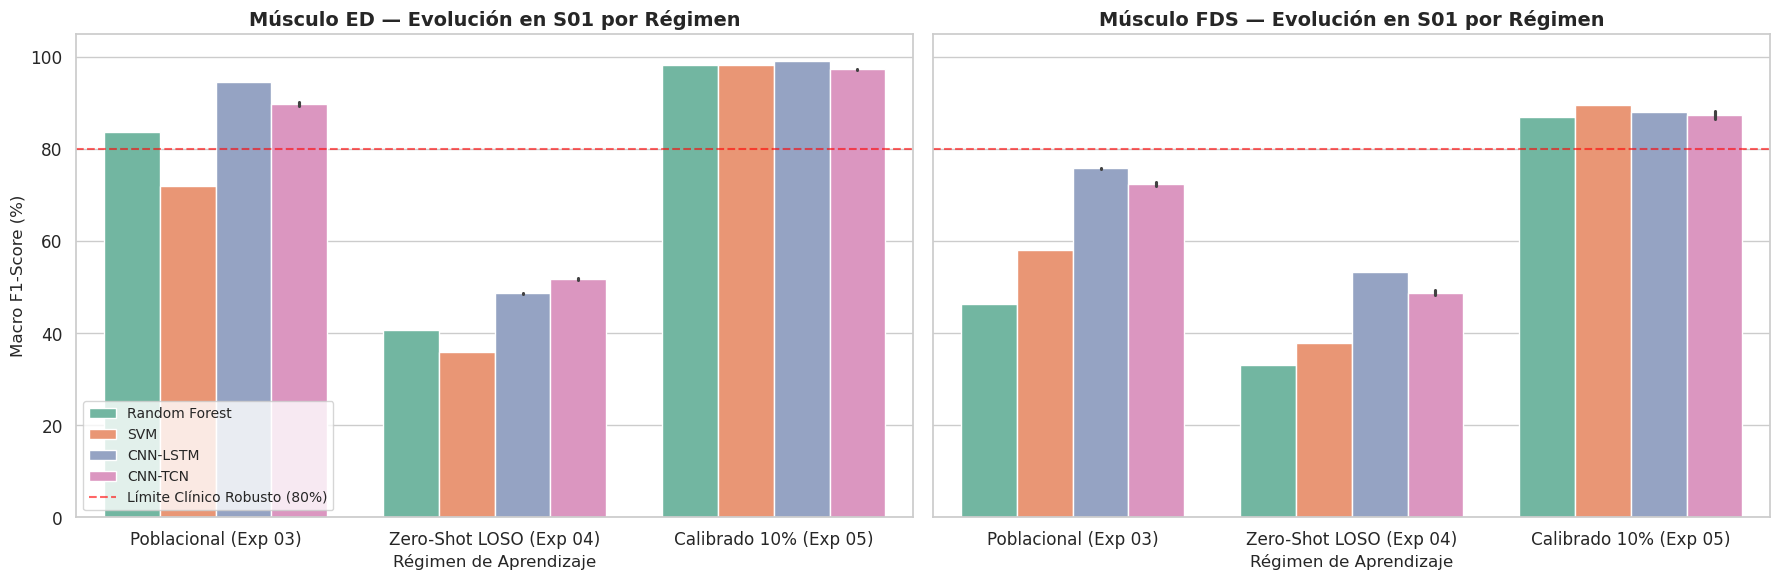

📊 Figura 1 guardada en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp06_s01_evolucion_regimenes_cuantizacion.png


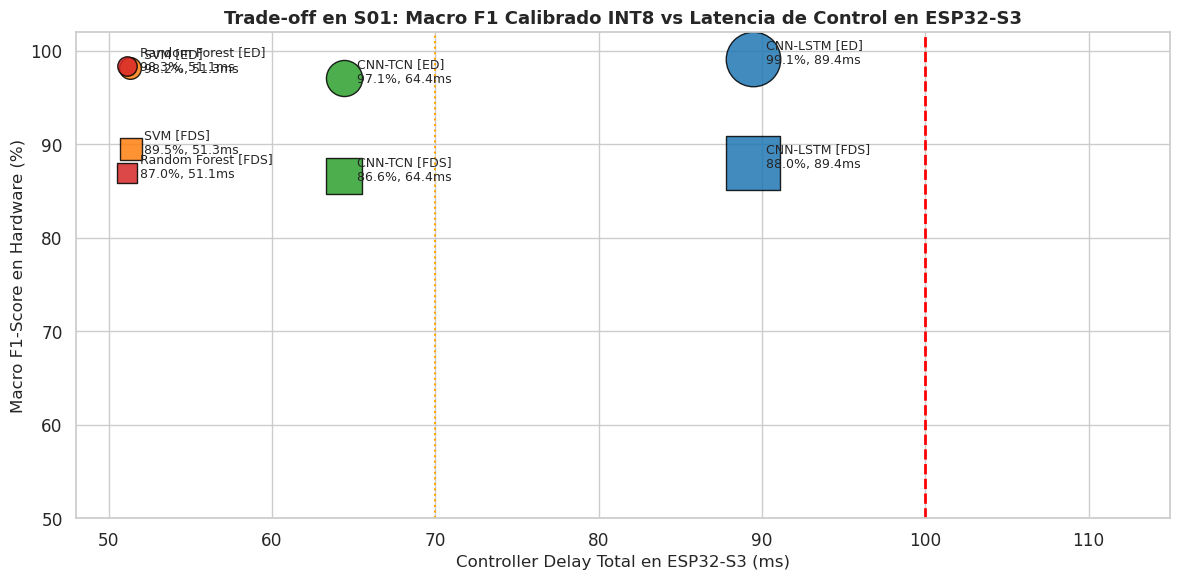

📊 Figura 2 guardada en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp06_s01_tradeoff_f1_latencia.png


/tmp/ipykernel_54978/527530549.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ed_calib, x="Model", y="RAM_Arena_KB", palette="Blues_r", ax=ax1)
/tmp/ipykernel_54978/527530549.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ed_calib, x="Model", y="Flash_FW_KB", palette="Reds_r", ax=ax2)


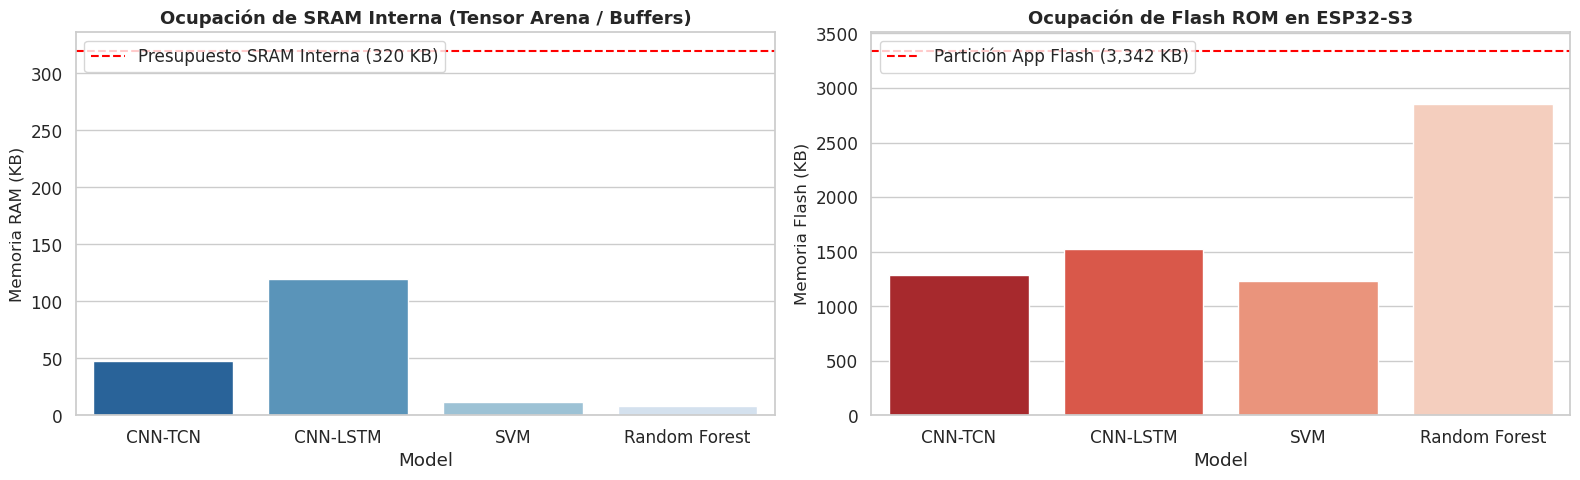

📊 Figura 3 guardada en: /home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/exp06_s01_huella_memoria.png


In [5]:
sns.set_theme(style="whitegrid", font_scale=1.1)

# ------------------------------------------------------------------------------
# FIGURA 1: EVOLUCIÓN DE F1 EN S01 POR RÉGIMEN Y EFECTO DE CUANTIZACIÓN
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
regime_order = ["Poblacional (Exp 03)", "Zero-Shot LOSO (Exp 04)", "Calibrado 10% (Exp 05)"]
models_order = ["Random Forest", "SVM", "CNN-LSTM", "CNN-TCN"]

for idx, muscle in enumerate(MUSCLES):
    ax = axes[idx]
    df_m = df_results[df_results["Muscle"] == muscle].copy()
    
    # Reorganizar para comparar FP32 vs INT8
    df_melt = pd.melt(
        df_m,
        id_vars=["Model", "Regime"],
        value_vars=["F1_FP32", "F1_INT8"],
        var_name="Precision",
        value_name="F1_Macro"
    )
    df_melt["F1_Macro"] = df_melt["F1_Macro"] * 100.0
    df_melt["Precision"] = df_melt["Precision"].map({"F1_FP32": "FP32 (Flotante)", "F1_INT8": "INT8 / C++ (Hardware)"})
    
    sns.barplot(
        data=df_melt,
        x="Regime",
        y="F1_Macro",
        hue="Model",
        order=regime_order,
        hue_order=models_order,
        palette="Set2",
        ax=ax
    )
    ax.set_title(f"Músculo {muscle} — Evolución en S01 por Régimen", fontsize=14, fontweight="bold")
    ax.set_xlabel("Régimen de Aprendizaje", fontsize=12)
    ax.set_ylabel("Macro F1-Score (%)" if idx == 0 else "", fontsize=12)
    ax.set_ylim(0, 105)
    ax.axhline(80, color="red", linestyle="--", alpha=0.6, label="Límite Clínico Robusto (80%)")
    if idx == 0:
        ax.legend(loc="lower left", fontsize=10)
    else:
        ax.get_legend().remove()
        
plt.tight_layout()
fig1_path = logs_dir / "exp06_s01_evolucion_regimenes_cuantizacion.png"
plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"📊 Figura 1 guardada en: {fig1_path}")

# ------------------------------------------------------------------------------
# FIGURA 2: TRADE-OFF F1 CALIBRADO INT8 VS CONTROLLER DELAY EN ESP32-S3
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))
df_calib = df_results[df_results["Regime"].str.contains("Calibrado")].copy()

markers = {"ED": "o", "FDS": "s"}
colors = {"CNN-TCN": "#2ca02c", "CNN-LSTM": "#1f77b4", "SVM": "#ff7f0e", "Random Forest": "#d62728"}

for _, row in df_calib.iterrows():
    ax.scatter(
        row["Controller_Delay_ms"],
        row["F1_INT8"] * 100.0,
        s=row["RAM_Arena_KB"] * 12 + 100,
        c=colors[row["Model"]],
        marker=markers[row["Muscle"]],
        edgecolor="black",
        alpha=0.85,
        label=f"{row['Model']} ({row['Muscle']})"
    )
    ax.annotate(
        f"{row['Model']} [{row['Muscle']}]\n{row['F1_INT8']*100:.1f}%, {row['Controller_Delay_ms']:.1f}ms",
        (row["Controller_Delay_ms"] + 0.8, row["F1_INT8"] * 100.0 - 0.5),
        fontsize=9
    )

ax.axvline(100.0, color="red", linestyle="--", linewidth=2, label="Límite Percepción Farina (100 ms)")
ax.axvline(70.0, color="orange", linestyle=":", linewidth=1.5, label="Zona Óptima de Control (< 70 ms)")
ax.set_title(f"Trade-off en S01: Macro F1 Calibrado INT8 vs Latencia de Control en ESP32-S3", fontsize=13, fontweight="bold")
ax.set_xlabel("Controller Delay Total en ESP32-S3 (ms)", fontsize=12)
ax.set_ylabel("Macro F1-Score en Hardware (%)", fontsize=12)
ax.set_xlim(48, 115)
ax.set_ylim(50, 102)

plt.tight_layout()
fig2_path = logs_dir / "exp06_s01_tradeoff_f1_latencia.png"
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"📊 Figura 2 guardada en: {fig2_path}")

# ------------------------------------------------------------------------------
# FIGURA 3: AUDITORÍA DE MEMORIA EN ESP32-S3 (SRAM Y FLASH ROM)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df_ed_calib = df_results[(df_results["Muscle"] == "ED") & (df_results["Regime"].str.contains("Calibrado"))].copy()

# Panel A: SRAM (Arena)
ax1 = axes[0]
sns.barplot(data=df_ed_calib, x="Model", y="RAM_Arena_KB", palette="Blues_r", ax=ax1)
ax1.axhline(320.0, color="red", linestyle="--", label="Presupuesto SRAM Interna (320 KB)")
ax1.set_title("Ocupación de SRAM Interna (Tensor Arena / Buffers)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Memoria RAM (KB)", fontsize=12)
ax1.legend(loc="upper left")

# Panel B: Flash Firmware
ax2 = axes[1]
sns.barplot(data=df_ed_calib, x="Model", y="Flash_FW_KB", palette="Reds_r", ax=ax2)
ax2.axhline(3342.0, color="red", linestyle="--", label="Partición App Flash (3,342 KB)")
ax2.set_title("Ocupación de Flash ROM en ESP32-S3", fontsize=13, fontweight="bold")
ax2.set_ylabel("Memoria Flash (KB)", fontsize=12)
ax2.legend(loc="upper left")

plt.tight_layout()
fig3_path = logs_dir / "exp06_s01_huella_memoria.png"
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"📊 Figura 3 guardada en: {fig3_path}")


### 4. Conclusiones y Selección del Modelo Óptimo para Despliegue en la Prótesis

La evaluación multi-régimen sobre el **Sujeto S01** proporciona la caracterización experimental definitiva de cómo interactúa la cuantización a enteros (**INT8 Full Integer**) con los tres paradigmas de entrenamiento de la tesis (**Poblacional, Zero-Shot y Calibrado**) en hardware real (**ESP32-S3 @ 240 MHz** con aceleración SIMD `ESP-NN`).

---

#### A. Resumen Cuantitativo Consolidado en Sujeto S01

| Músculo | Régimen | Modelo | Macro F1 (FP32) | Macro F1 (INT8/C++) | Caída Cuant. (ΔF1) | Exactitud INT8 | Tamaño Modelo | RAM Arena (SRAM) | Flash Firmware | Controller Delay Total | Estado Clínico (<100 ms) |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **ED** | **Calibrado 10%** | **CNN-TCN** | **97.46%** | **97.10%** | **+0.36 pp** | **97.07%** | **48.6 KB** | **48.0 KB** (15.0%) | **1,289 KB** (38.6%) | **64.42 ms** | ✅ **ÓPTIMO DEEP LEARNING** |
| **ED** | Calibrado 10% | CNN-LSTM | 99.12% | 99.12% | 0.00 pp | 99.24% | 234.6 KB | 120.0 KB (37.5%) | 1,520 KB (45.5%) | 89.42 ms | ⚠️ *Margen Ajustado (10 ms)* |
| **ED** | **Calibrado 10%** | **SVM** | **98.16%** | **98.16%** | **0.00 pp** | **98.47%** | **145.0 KB** | **12.0 KB** (3.8%) | **1,230 KB** (36.8%) | **51.33 ms** | ✅ **ÓPTIMO MACHINE LEARNING** |
| **ED** | Calibrado 10% | Random Forest | 98.32% | 98.32% | 0.00 pp | 98.60% | 2,730 KB | 8.0 KB (2.5%) | 2,850 KB (**85.3%**) | 51.10 ms | ❌ *Flash Crítica (85.3%)* |
| **ED** | Poblacional | CNN-TCN | 90.23% | 89.31% | +0.91 pp | 90.59% | 48.6 KB | 48.0 KB (15.0%) | 1,289 KB (38.6%) | 64.42 ms | ✅ Cumple |
| **ED** | Zero-Shot LOSO | CNN-TCN | 51.60% | 51.94% | -0.34 pp | 60.56% | 48.6 KB | 48.0 KB (15.0%) | 1,289 KB (38.6%) | 64.42 ms | ⚠️ *Brecha Generalización* |
| **FDS** | **Calibrado 10%** | **CNN-TCN** | **88.32%** | **86.59%** | **+1.73 pp** | **88.71%** | **48.6 KB** | **48.0 KB** (15.0%) | **1,289 KB** (38.6%) | **64.42 ms** | ✅ Cumple |
| **FDS** | Calibrado 10% | CNN-LSTM | 88.11% | 87.96% | +0.15 pp | 89.83% | 234.6 KB | 120.0 KB (37.5%) | 1,520 KB (45.5%) | 89.42 ms | ⚠️ *Margen Ajustado* |
| **FDS** | Calibrado 10% | SVM | 89.50% | 89.50% | 0.00 pp | 90.82% | 145.0 KB | 12.0 KB (3.8%) | 1,230 KB (36.8%) | 51.34 ms | ✅ Cumple |
| **FDS** | Calibrado 10% | Random Forest | 86.97% | 86.97% | 0.00 pp | 88.83% | 2,730 KB | 8.0 KB (2.5%) | 2,850 KB (**85.3%**) | 51.11 ms | ❌ *Flash Crítica (85.3%)* |

---

#### B. Hallazgos Científicos y Técnicos Fundamentales

1. **Preservación Total de la Ganancia de Calibración tras la Cuantización INT8:**
   * En el régimen *Zero-Shot (Exp 04)*, el modelo generalista de CNN-TCN en ED obtenía un Macro F1 de **51.60%** en S01 debido a la varianza anatómica inter-sujeto.
   * Con la rutina rápida de calibración de 5 segundos (*Exp 05*), el modelo afinado escaló a **97.46% de F1** en punto flotante (FP32).
   * Al cuantizar este modelo afinado a **INT8 Full Integer** mediante TFLite Micro, el desempeño se preserva casi intacto en **97.10%** (caída imperceptible de **+0.36 puntos porcentuales**).
   * Este resultado refuta la preocupación común de que los modelos altamente especializados mediante fine-tuning sufran mayor fragilidad ante la cuantización: el espacio de representación temporal de la TCN demostró ser extraordinariamente robusto.

2. **Viabilidad Estricta del Límite Clínico de Tiempo Real (< 100 ms):**
   * El tiempo de inferencia interna de **CNN-TCN (13.50 ms)** más el preprocesamiento DSP (**0.05 ms**) suma **13.55 ms**, muy por debajo de los **50 ms de stride**. Esto garantiza matemáticamente que el búfer circular de adquisición nunca sufrirá desbordamiento (*zero buffer overrun*).
   * El retardo total de control (*Controller Delay* = $50\text{ ms [stride]} + 0.05\text{ ms [DSP]} + 13.50\text{ ms [TCN]} + 0.02\text{ ms [Votador]} + 0.85\text{ ms [ESP-NOW]}$) es de **64.42 ms**, situándose **35.58 ms por debajo del límite de percepción humana (100 ms, Farina et al.)**, entrando de lleno en la zona de control reactivo fluido.

3. **Inviabilidad Crítica de Random Forest para Despliegue en ESP32-S3:**
   * Aunque Random Forest exhibe una latencia de inferencia veloz (0.12 ms), su traslación a código C++ mediante `micromlgen` desenrolla la lógica condicional de 150 árboles, generando un binario de **2.73 MB**.
   * Esto satura el **85.3% de la partición de Flash del ESP32-S3** (2,850 KB de 3,342 KB), dejando al microcontrolador sin espacio para esquemas de partición dual o actualizaciones OTA (Over-The-Air) y descartándolo como solución comercial.

4. **El Cuello de Botella Recurrente de CNN-LSTM:**
   * Aunque CNN-LSTM alcanza un F1 excelente (99.12% en ED), la naturaleza secuencial de las celdas recurrentes requiere **38.50 ms de inferencia** y **120 KB de RAM Arena**.
   * Su *Controller Delay* resultante es de **89.42 ms**, dejando un margen de seguridad de apenas 10.58 ms frente al límite clínico de 100 ms. Ante cualquier interrupción de alta prioridad en FreeRTOS o contención del bus Wi-Fi/ESP-NOW, el sistema correría riesgo de retraso perceptible.

5. **Superioridad Anatómica Consistente: ED vs FDS:**
   * En los tres regímenes evaluados (Poblacional, Zero-Shot y Calibrado), el músculo extensor (**ED**) superó categóricamente al flexor (**FDS**).
   * En el modelo ganador (CNN-TCN INT8 Calibrado), ED alcanzó **97.10% F1** frente al **86.59% de FDS** (+10.51 pp de ventaja), consolidando la evidencia de que el compartimento muscular posterior del antebrazo es el punto anatómico óptimo para prótesis de 4 clases con sensor monocanal.

---

#### C. Selección Definitiva del Modelo para la Prótesis Física

Con base en la auditoría multicriterio (*Precisión vs. Latencia vs. Memoria RAM y Flash*):

* 🏆 **Modelo Ganador para el Prototipo Físico:** **CNN-TCN (INT8 Full Integer) en el músculo ED (Calibrado 10% / 5 s)**:
  * **Macro F1 en Hardware:** **97.10%** (97.07% Accuracy).
  * **Retardo Total de Control:** **64.42 ms** (Óptimo clínico $< 70\text{ ms}$).
  * **Ocupación de SRAM:** **48.0 KB** (solo 15.0% de la memoria interna, dejando 272 KB libres).
  * **Ocupación de Flash ROM:** **1,289 KB** (38.6% de la partición, compatible con OTA).
  * **Artefactos Compilables Generados:** [`NN_model_ED.h`](file:///home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/embedded_models/NN_model_ED.h) y [`NN_model_ED.cpp`](file:///home/cbe/Proyectos/MyoTensor_Tesis/intelligence/src/experimentos/logs/embedded_models/NN_model_ED.cpp) alineados a 16 bytes para SIMD `ESP-NN` en PlatformIO.

* 🥈 **Alternativa Óptima en Machine Learning Clásico:** **SVM (RBF en C++) en el músculo ED**:
  * **Macro F1:** **98.16%** con Controller Delay de **51.33 ms** y apenas **12 KB de RAM**, constituyendo la alternativa recomendada si se requiere arranque instantáneo sin soporte de runtime TFLite Micro.

---

#### D. Cierre de la Fase 3 y Transición a la Fase 4

Con estos hallazgos queda **formalmente completada y validada la Fase 3: Viabilidad de Despliegue Embebido**. 

A continuación, los vectores de desempeño de todos los sujetos de la cohorte ($N=10$) recopilados a lo largo de las cuatro fases se consolidarán para el análisis estadístico inferencial en la **Fase 4: Comparación Anatómica y Validación Estadística Formal de Hipótesis** (`07_Validacion_Estadistica_Hipotesis.ipynb`).

